# How candidates use Win: usage groups (DATA-2690, v1)

Describes how Win candidates use the product beyond counts: how much they act, which areas they combine,
what they skip, and in what order they pick things up. Results only, no election outcomes (those are
DATA-2678, which uses these groups as one of its cuts).

**Who:** Win candidates who signed up from 2026-07-01 with at least 14 days on Win before the earlier of
their election or the run date. Staff, demo accounts and non-latest campaigns excluded.
**Spec:** `usage_archetypes_brief.yaml` (decisions from the 2026-10-28 checkpoint are at the bottom).
**Inputs:** `datasets/` written by `build_working_set.py`; groups and labels from `analyze.py`.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

HERE = Path.cwd()
sys.path.insert(0, str(HERE))
import analyze as A  # noqa: E402

ws, _ = A.load()
asg = pd.read_parquet(HERE / "datasets" / "assignments.parquet").set_index("user_id")
ws = ws.join(asg[["group"]])
res = json.loads((HERE / "results.json").read_text())
pd.set_option("display.max_colwidth", 60)
print(
    f"Run {res['run_ts']} UTC. Eligible users {len(ws):,}: onboarded {ws['onboarded'].sum():,}, "
    f"activated {ws['activated'].sum():,}, Pro {ws['is_pro'].sum():,}."
)

Run 2026-10-28 17:34:12 UTC. Eligible users 1,802: onboarded 789, activated 214, Pro 345.


## Definitions

- **Action-day:** a distinct day on which the user did something in an area: sent or drafted outreach,
  built or exported a voter list, asked the AI assistant, requested a story rewrite or edited an issue,
  or started opponent research. Page views, onboarding, the campaign plan, paywalls and compliance
  screens don't count.
- **Areas:** outreach, voter data, AI assistant, story and issues, opponent research.
- **Onboarded:** viewed the dashboard within 14 days of signup. **Activated:** the governed definition
  (`users_win_base.is_activated`, sent outreach).

## 1. Most candidates barely act

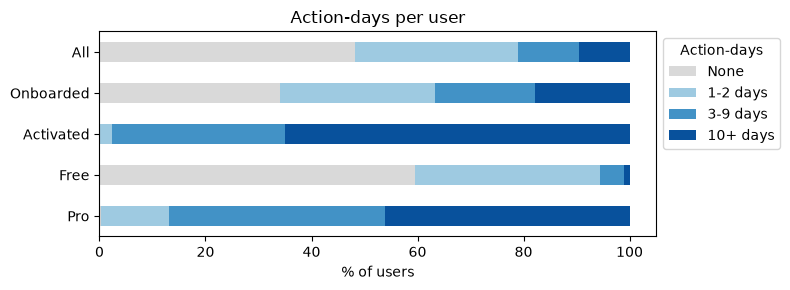

,None,1-2 days,3-9 days,10+ days,n
All,48.0,31.0,11.0,10.0,1802
Onboarded,34.0,29.0,19.0,18.0,789
Activated,0.0,2.0,33.0,65.0,214
Free,60.0,35.0,5.0,1.0,1457
Pro,0.0,13.0,41.0,46.0,345


In [2]:
bands = pd.cut(ws["area_days"], [-1, 0, 2, 9, 1e9], labels=["None", "1-2 days", "3-9 days", "10+ days"])
cohorts = {
    "All": ws.index,
    "Onboarded": ws.index[ws["onboarded"]],
    "Activated": ws.index[ws["activated"]],
    "Free": ws.index[~ws["is_pro"]],
    "Pro": ws.index[ws["is_pro"]],
}
tab = pd.DataFrame(
    {k: bands[v].value_counts(normalize=True).reindex(bands.cat.categories) for k, v in cohorts.items()}
).T
ax = (tab * 100).plot.barh(stacked=True, figsize=(8, 3), color=["#d9d9d9", "#9ecae1", "#4292c6", "#08519c"])
ax.set_xlabel("% of users")
ax.invert_yaxis()
ax.legend(title="Action-days", bbox_to_anchor=(1, 1))
ax.set_title("Action-days per user")
plt.tight_layout()
plt.show()
(tab * 100).round(0).assign(n=[len(v) for v in cohorts.values()])

## 2. Opening an area isn't using it (onboarded users)

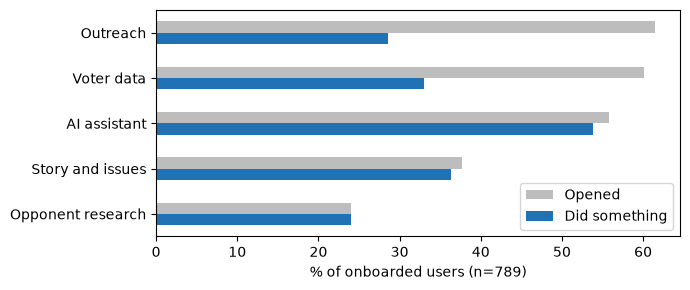

,Opened,Did something
Outreach,61.0,29.0
Voter data,60.0,33.0
AI assistant,56.0,54.0
Story and issues,38.0,36.0
Opponent research,24.0,24.0


In [3]:
onb = ws[ws["onboarded"]]
oa = pd.DataFrame(
    {
        "Opened": [(onb[f"view_{a}"] > 0).mean() * 100 for a in A.AREAS],
        "Did something": [(onb[f"days_{a}"] > 0).mean() * 100 for a in A.AREAS],
    },
    index=[A.AREA_NAMES[a] for a in A.AREAS],
)
ax = oa.plot.barh(figsize=(7, 3), color=["#bdbdbd", "#2171b5"])
ax.invert_yaxis()
ax.set_xlabel(f"% of onboarded users (n={len(onb)})")
plt.tight_layout()
plt.show()
oa.round(0)

## 3. Free users act almost only in the AI assistant and story

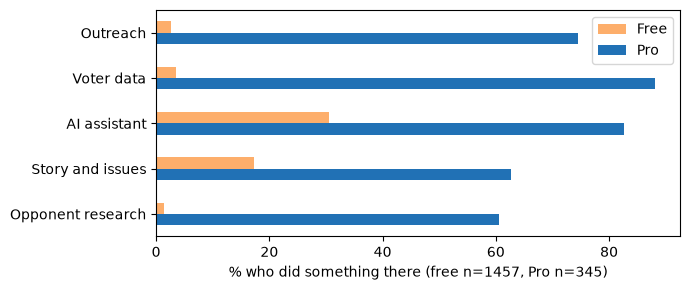

,Free,Pro
Outreach,3.0,74.0
Voter data,4.0,88.0
AI assistant,31.0,83.0
Story and issues,17.0,63.0
Opponent research,1.0,61.0


In [4]:
fp = pd.DataFrame(
    {
        "Free": [(ws.loc[~ws["is_pro"], f"days_{a}"] > 0).mean() * 100 for a in A.AREAS],
        "Pro": [(ws.loc[ws["is_pro"], f"days_{a}"] > 0).mean() * 100 for a in A.AREAS],
    },
    index=[A.AREA_NAMES[a] for a in A.AREAS],
)
ax = fp.plot.barh(figsize=(7, 3), color=["#fdae6b", "#2171b5"])
ax.invert_yaxis()
ax.set_xlabel(f"% who did something there (free n={(~ws['is_pro']).sum()}, Pro n={ws['is_pro'].sum()})")
plt.tight_layout()
plt.show()
fp.round(0)

## 4. Usage groups, free and Pro grouped separately

Users with 3+ action-days, grouped by how their action-days split across the five areas (k-means on the
square root of each area's share; k picked for stability on resampling, then fit). Free and Pro are
grouped separately because a pooled grouping mostly sorts out who is Pro (section 6). Groups under 30
users are shown as counts only.

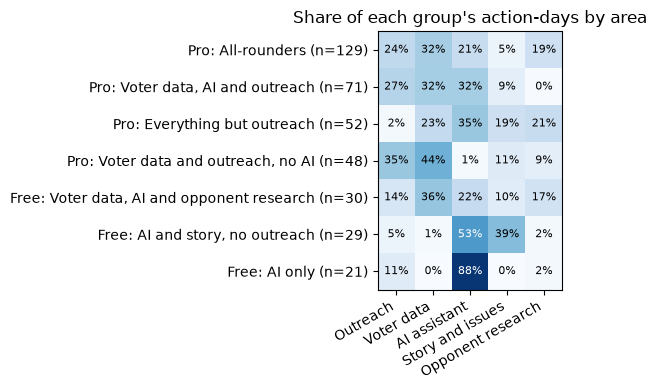

{'Pro': 'k=4, n=300', 'Free': 'k=3, n=80'}


In [5]:
mix = pd.DataFrame(res["group_mix"]).T
mix = mix.sort_values("n", ascending=False)
shares = mix.drop(columns="n")
fig, ax = plt.subplots(figsize=(8, 4))
im = ax.imshow(shares.to_numpy(), cmap="Blues", vmin=0, vmax=0.9)
ax.set_xticks(range(shares.shape[1]), shares.columns, rotation=30, ha="right")
ax.set_yticks(range(len(shares)), [f"{g} (n={int(n)})" for g, n in mix["n"].items()])
for i in range(shares.shape[0]):
    for j in range(shares.shape[1]):
        v = shares.iat[i, j]
        ax.text(
            j, i, f"{v:.0%}", ha="center", va="center", color="white" if v > 0.45 else "black", fontsize=8
        )
ax.set_title("Share of each group's action-days by area")
plt.tight_layout()
plt.show()
print({t: f"k={v['k']}, n={v['n']}" for t, v in res["tier_k"].items()})

## 5. What each group does and skips

In [6]:
rows = []
for p in res["profiles"]:
    small = p["n"] < 30
    r = {"group": p["group"], "n": p["n"], "activated": p["activated"]}
    if not small:
        r.update(
            {
                "sent outreach": f"{p['sent_outreach_share']:.0%}",
                "AI chat users": f"{p['chat_users_share']:.0%}",
                "story rewrite": f"{p['story_rewrite_users']:.0%}",
                "opp. research started": f"{p['opp_research_started']:.0%}",
                "never used": ", ".join(A.AREA_NAMES[a] for a, v in p["share_never_used"].items() if v >= 0.5)
                or "-",
                "action-days/week": round(p["median_area_days_per_week"], 2),
            }
        )
    rows.append(r)
pd.DataFrame(rows).set_index("group").astype(object).fillna("count only")

,n,activated,sent outreach,AI chat users,story rewrite,opp. research started,never used,action-days/week
group,,,,,,,,
No area use,869,0,0%,0%,0%,0%,"Outreach, Voter data, AI assistant, Story and issues, Op...",0.0
Light touch (1-2 days),553,5,2%,64%,37%,1%,"Outreach, Voter data, Story and issues, Opponent research",0.15
Pro: All-rounders,129,102,96%,96%,33%,40%,-,1.75
"Pro: Voter data, AI and outreach",71,47,86%,100%,28%,4%,Opponent research,1.21
Pro: Everything but outreach,52,5,15%,87%,40%,35%,Outreach,0.54
"Pro: Voter data and outreach, no AI",48,40,88%,21%,31%,15%,AI assistant,1.6
"Free: Voter data, AI and opponent research",30,12,40%,70%,7%,20%,-,0.7
"Free: AI and story, no outreach",29,1,count only,count only,count only,count only,count only,count only
Free: AI only,21,2,count only,count only,count only,count only,count only,count only


In [7]:
order = [p["group"] for p in res["profiles"]]
gs = pd.DataFrame(res["group_shares"]).reindex(order) * 100
gs.round(0).astype(int).astype(str) + "%"

,all,onboarded,activated,free,Pro
No area use,48%,34%,0%,60%,0%
Light touch (1-2 days),31%,29%,2%,35%,13%
Pro: All-rounders,7%,14%,48%,0%,37%
"Pro: Voter data, AI and outreach",4%,6%,22%,0%,21%
Pro: Everything but outreach,3%,5%,2%,0%,15%
"Pro: Voter data and outreach, no AI",3%,5%,19%,0%,14%
"Free: Voter data, AI and opponent research",2%,3%,6%,2%,0%
"Free: AI and story, no outreach",2%,3%,0%,2%,0%
Free: AI only,1%,2%,1%,1%,0%


## 6. Are the groups more than payment, volume or timing?

- Pooled across free and Pro, the groups line up strongly with being Pro, which is why they are split.
- Within Pro, the groups differ in volume (expected: some do more) but hardly by tenure or how close the
  election is.

In [8]:
print(
    "\n".join(
        line
        for line in (HERE / "results.txt").read_text().splitlines()
        if line.startswith(
            (
                "== 5",
                "  volume",
                "  tenure",
                "  days to election",
                "  signup_month",
                "  office_level",
                "  experienced vs",
                "  pooled",
                "  agreement",
                "  clustering on visit",
            )
        )
    )
)

== 5. Is it more than volume or timing? (Pro groups) ==
  volume (log area-days/week) explained by group: eta^2 = 0.19
  tenure (days on Win) explained by group: eta^2 = 0.06
  days to election at run explained by group: eta^2 = 0.02
  signup_month vs group: Cramer's V = 0.20
  office_level vs group: Cramer's V = 0.08
  experienced vs group: Cramer's V = 0.07
== 5b. Robustness ==
  pooled (free and Pro together): k=3, stability 0.90; Pro vs pooled group Cramer's V = 0.55 (why the tiers are split)
  agreement between pooled and per-tier groups: ARI 0.37
  clustering on visit-days instead of action-days (pooled): 605 users clear the floor; agreement with the action-day clusters on the 380 in both: ARI 0.14


## 7. Journeys: which area candidates use first

In [9]:
for name, sub in [("onboarded", ws[ws["onboarded"]]), ("activated", ws[ws["activated"]])]:
    print(name)
    print(A.journeys(sub).head(8).to_string())
    print()
firsts = ws[[f"first_{a}" for a in A.AREAS]].fillna(pd.Timestamp("2100-01-01"))
fa = firsts.idxmin(axis=1).where(ws["area_days"] > 0).str.removeprefix("first_").map(A.AREA_NAMES)
(
    ws.assign(first_area=fa)
    .dropna(subset=["first_area"])
    .groupby("first_area")
    .agg(n=("activated", "size"), activated=("activated", "mean"), pro=("is_pro", "mean"))
    .sort_values("n", ascending=False)
    .round(2)
)

onboarded
AI assistant                                           119
AI assistant > Story and issues                         62
Story and issues                                        48
Outreach > Voter data > AI assistant                    23
Voter data > AI assistant > Story and issues            21
AI assistant > Story and issues > Voter data            17
AI assistant > Story and issues > Opponent research     16
AI assistant > Story and issues > Outreach              16

activated
Outreach > Voter data > AI assistant                   19
AI assistant > Story and issues > Outreach             16
AI assistant > Outreach > Voter data                   16
Voter data > AI assistant > Story and issues           12
AI assistant > Story and issues > Voter data           12
Story and issues > Outreach > Voter data               11
AI assistant > Story and issues > Opponent research    10
Voter data > Story and issues > Outreach                9



,n,activated,pro
first_area,,,
AI assistant,539,0.14,0.26
Story and issues,204,0.23,0.32
Voter data,109,0.41,0.78
Outreach,68,0.56,0.66
Opponent research,13,0.54,0.85


Activation by first area is descriptive only: outreach-first users are mostly Pro, so this is not a
claim that starting with outreach causes activation.

## 8. What candidates ask the AI assistant (totals only)

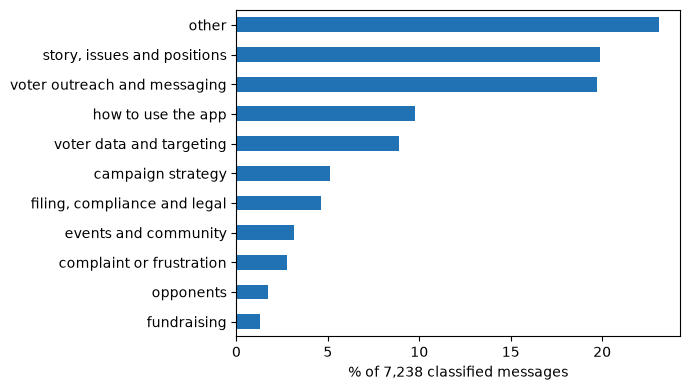

In [10]:
tcols = [c for c in ws.columns if c.startswith("topic_")]
tot = ws[tcols].sum().sort_values()
ax = (
    (tot / tot.sum() * 100)
    .rename(lambda c: c.removeprefix("topic_"))
    .plot.barh(figsize=(7, 4), color="#2171b5")
)
ax.set_xlabel(f"% of {int(tot.sum()):,} classified messages")
plt.tight_layout()
plt.show()

Topics are a majority vote of three models over each message, run in the warehouse; only per-user
counts leave it. 23% land in "other", not yet characterized.

## 9. What we checked and left out

- **Rule-based labels.** Heavy messenger, field organizer, list builder and researcher are 91 to 95% Pro,
  so they restate Pro. "Story and positions focused" (redefined at the checkpoint) holds 12 users.
- **Tech comfort.** Three inferred signals (how-to share of AI questions, abandoned flows, onboarding
  speed) don't agree with each other (pairwise correlations 0.13 or less), so no label is reported. An
  open problem, with no good leads yet.
- **Visit-days instead of action-days** give different groups (agreement 0.14), so the choice to count
  actions matters. Actions are used because most outreach and voter-data visits involve no action.

In [11]:
print(
    "\n".join(
        line
        for line in (HERE / "results.txt").read_text().splitlines()
        if line.startswith(
            ("  Heavy", "  Field", "  List", "  AI-led", "  Researcher", "  Story and", "  Dabbler")
        )
    )
)
tc = A.tech_comfort(ws)
tc[["howto_share", "abandon_rate", "onboarding_minutes"]].corr(method="spearman").round(2)

  Story and issues   opened 27%  acted 26%  | onboarded opened 38% acted 36%
  Heavy messenger            all  107 (6%)  onboarded   87  activated  105  Pro share 95%
  Field organizer            all   76 (4%)  onboarded   65  activated   65  Pro share 95%
  List builder               all  163 (9%)  onboarded  127  activated  133  Pro share 93%
  AI-led                     all   95 (5%)  onboarded   64  activated   11  Pro share 27%
  Researcher                 all  164 (9%)  onboarded  135  activated  105  Pro share 91%
  Story and positions focused all   12 (1%)  onboarded    6  activated    0  Pro share 8%
  Dabbler                    all  431 (24%)  onboarded  161  activated    1  Pro share 5%


,howto_share,abandon_rate,onboarding_minutes
howto_share,1.00,-0.13,0.09
abandon_rate,-0.13,1.00,-0.06
onboarding_minutes,0.09,-0.06,1.00
